In [1]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [2]:


import torch
from torch import linalg as LA


import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
from datasets import load_dataset

In [3]:
arc = load_dataset("allenai/ai2_arc", "ARC-Challenge", split="test")

In [4]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

W1023 17:34:24.199000 38559 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [5]:
def time_counter(no_of_threads: int, model, tokenizer, prompts: list,
                 results: list, max_new_tokens: int = 128, repeats: int = 3):
    

    torch.set_num_threads(int(no_of_threads))
    
    print(torch.get_num_threads())
    time.sleep(2)
    for x in range(1):
        n_dict={}
        n_lst=[]
        
        messages = [{"role": "user", "content": prompts[x]}]
        text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        model_inputs = tokenizer(text, return_tensors="pt").to(model.device)
        for i in range(repeats):
            start_time=time.perf_counter()
            out_put_ids=model.generate(max_new_tokens=max_new_tokens,**model_inputs,do_sample=False)
            


            end_time=time.perf_counter()
            n_lst.append(end_time-start_time)
        mean=statistics.mean(n_lst)
        stndev=statistics.stdev(n_lst)
        n_dict['thread']=torch.get_num_threads()
        n_dict['mean']=mean
        n_dict['stdev']=stndev
        results.append(n_dict)

    
    
    
    
    
  
    
    

In [6]:
def make_prompt(item):
    lines = [item["question"]]
    for label, text in zip(item["choices"]["label"], item["choices"]["text"]):
        lines.append(f"{label}. {text}")
    lines.append("Answer with the letter and briefly explain why.")
    return "\n".join(lines)

prompts = [make_prompt(arc[i]) for i in range(10)]



In [7]:
results=[]
prompts = [make_prompt(arc[i]) for i in range(10)]
with open("prompts_arc10.json", "w") as f:
    json.dump(prompts, f, indent=2)
with open("prompts_arc10.json") as f:
    prompts = json.load(f)


In [8]:
for i in range(1,13):
    time_counter(i,model_hf,tokenizer,prompts,results)

1
2
3
4
5
6
7
8
9
10
11
12


In [9]:
results

[{'thread': 1, 'mean': 16.068080458329252, 'stdev': 0.49116794668755115},
 {'thread': 2, 'mean': 9.444541499663805, 'stdev': 0.051933581619289744},
 {'thread': 3, 'mean': 9.572467291999297, 'stdev': 0.007049980943546929},
 {'thread': 4, 'mean': 9.684445235999496, 'stdev': 0.10137388826851926},
 {'thread': 5, 'mean': 9.687790888662372, 'stdev': 0.0316497422600185},
 {'thread': 6, 'mean': 9.834674375000759, 'stdev': 0.14829127700092523},
 {'thread': 7, 'mean': 9.868605666328222, 'stdev': 0.04325592973250602},
 {'thread': 8, 'mean': 9.921404416997879, 'stdev': 0.014374938795735355},
 {'thread': 9, 'mean': 9.940524249997301, 'stdev': 0.06593714905605048},
 {'thread': 10, 'mean': 10.173154013667954, 'stdev': 0.10612137572049654},
 {'thread': 11, 'mean': 10.118492499668113, 'stdev': 0.02681641997256411},
 {'thread': 12, 'mean': 10.233924569663941, 'stdev': 0.07946768877652274}]

In [10]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.1.8
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=open, BUILD_TYPE=Release, COMMIT_SHA=Unknown, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_build_env/bin/arm64-apple-darwin20.0.0-clang++, CXX_FLAGS=-ftree-vectorize -fPIC -fstack-protector-strong -O2 -pipe -stdlib=libc++  -fmessage-length=0 -isystem /Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_pla

In [11]:
t1 = next(r['mean'] for r in results if r['thread'] == 1)

n_res = []
for r in results:
    n = r['thread']
    speedup = t1 / r['mean']
    efficiency = (speedup / n) * 100
    f = ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None   

    n_res.append({
        'threads': n,
        'mean': r['mean'],
        'speedup': speedup,
        'efficiency': efficiency,
        'serial_fraction': f,
    })

In [12]:
n_res

[{'threads': 1,
  'mean': 16.068080458329252,
  'speedup': 1.0,
  'efficiency': 100.0,
  'serial_fraction': None},
 {'threads': 2,
  'mean': 9.444541499663805,
  'speedup': 1.70130868278796,
  'efficiency': 85.065434139398,
  'serial_fraction': 17.55656220613475},
 {'threads': 3,
  'mean': 9.572467291999297,
  'speedup': 1.6785725109511747,
  'efficiency': 55.95241703170583,
  'serial_fraction': 39.361644505307346},
 {'threads': 4,
  'mean': 9.684445235999496,
  'speedup': 1.6591637483374053,
  'efficiency': 41.47909370843513,
  'serial_fraction': 47.028435338952555},
 {'threads': 5,
  'mean': 9.687790888662372,
  'speedup': 1.6585907605761534,
  'efficiency': 33.17181521152307,
  'serial_fraction': 50.36518529536369},
 {'threads': 6,
  'mean': 9.834674375000759,
  'speedup': 1.6338192649441952,
  'efficiency': 27.230321082403254,
  'serial_fraction': 53.44753644100207},
 {'threads': 7,
  'mean': 9.868605666328222,
  'speedup': 1.6282016934929013,
  'efficiency': 23.260024192755733,
  

In [17]:
%pip install matplotlib



  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 58.9 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 56.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 51.6 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


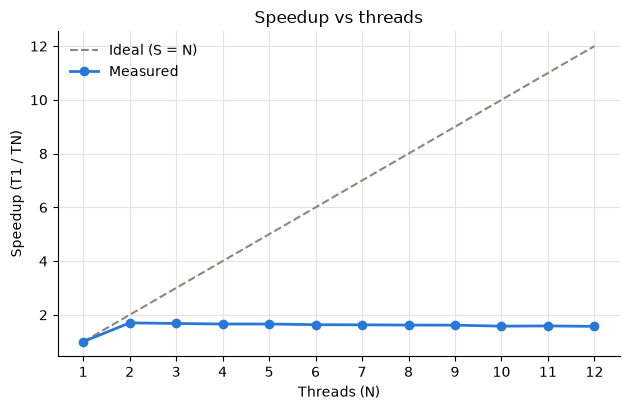

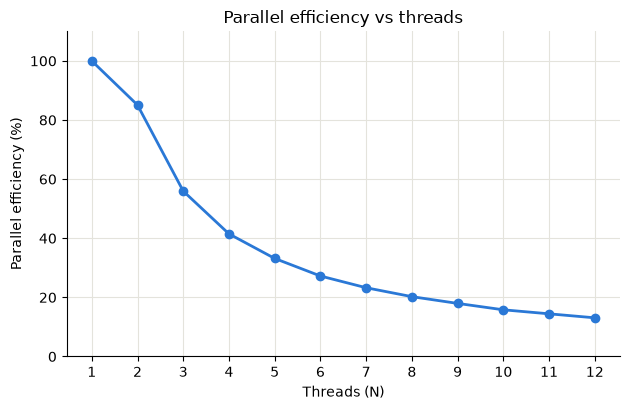

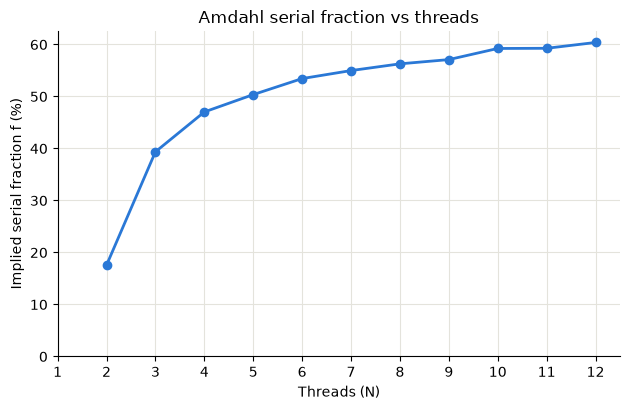

In [19]:
import matplotlib.pyplot as plt

RUN_NAME = "run4"   # change per run, used in the file names

threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]
# Amdahl serial fraction (%), skipping 1 thread
f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_speedup.png", dpi=200); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_efficiency.png", dpi=200); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_serial_fraction.png", dpi=200); plt.show()